# 1. Imports and global settings

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

In [2]:
import os
import random
import numpy as np
import torch
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")


In [3]:
# Reproducibility seed
# Using a fixed seed helps make results more repeatable
SEED = 42

def fix_random_seed(seed=SEED):
    """Fix random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.random.set_seed(seed)

fix_random_seed(SEED)

print("Setup complete")

Setup complete


# 2. Data loading

In [4]:
def load_data_pt(path):
    """
    Load one saved .pt split and convert it to Keras-friendly arrays.

    Returns
    -------
    images:
        NumPy array of shape [N, H, W, 3], values in [0, 1].

    labels:
        NumPy array of shape [N, 10].
        These are multi-hot labels used for training.
    """
    data = torch.load(path, map_location="cpu")

    # Convert [N, H, W] uint8 to [N, H, W, 1] float32.
    images = data["images"].numpy().astype("float32") / 255.0
    images = np.expand_dims(images, axis=-1)

    # ResNet expects 3-channel inputs, so replicate the grayscale channel.
    images = np.repeat(images, repeats=3, axis=-1)

    # Multi-label targets.
    labels = data["labels"].numpy().astype("float32")

    # Extra metadata, not required for model training.
    center_labels = data["center_labels"].numpy().astype("int64")
    count_labels = data["count_labels"].numpy().astype("int64")

    meta = {
        "center_labels": center_labels,
        "count_labels": count_labels,
        "num_digits": data["num_digits"].numpy().astype("int64"),
        "all_digit_labels": data["all_digit_labels"].numpy().astype("int64"),
        "all_positions": data["all_positions"].numpy().astype("int64"),
        "label_type": data.get("label_type", None),
    }

    return images, labels, meta


In [5]:
# File paths for train, validation, and test.
train_path = os.path.join("./data/train.pt")
val_path = os.path.join("./data/val.pt")
test_path = os.path.join("./data/test.pt")

# Load files if they exist.
if all(os.path.exists(p) for p in [train_path, val_path, test_path]):
    x_train, y_train, meta_train = load_data_pt(train_path)
    x_val, y_val, meta_val = load_data_pt(val_path)
    x_test, y_test, meta_test = load_data_pt(test_path)
    
    print("Data loaded successfully.")
    print("Train:", x_train.shape, y_train.shape)
    print("Val:  ", x_val.shape, y_val.shape)
    print("Test: ", x_test.shape, y_test.shape)
    print("You can now proceed to model training and evaluation.")
else:
    print("Dataset files not found yet.")

Data loaded successfully.
Train: (50000, 64, 64, 3) (50000, 10)
Val:   (10000, 64, 64, 3) (10000, 10)
Test:  (10000, 64, 64, 3) (10000, 10)
You can now proceed to model training and evaluation.


# 3. Visualization

In [6]:
def multihot_to_digits(multihot):
    """
    Convert a multi-hot vector into a list of digit labels.

    Example:
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 1]
        becomes
        [1, 4, 9]
    """
    return np.where(multihot >= 0.5)[0].tolist()


# 3. Define exact match accuracy metrics:

In [7]:
def exact_match_accuracy(y_true, y_pred):
    """
    Exact-match accuracy for multi-label classification.

    Steps:
    1. Convert predicted probabilities to binary labels using a threshold.
    2. Compare the whole predicted vector with the true vector.
    3. Count the sample as correct only if every label matches.

    This metric is strict but useful.
    """
    y_pred_binary = tf.cast(y_pred >= 0.5, tf.float32)

    # For each sample, check whether all 10 labels are correct.
    matches = tf.reduce_all(tf.equal(y_true, y_pred_binary), axis=1)

    return tf.reduce_mean(tf.cast(matches, tf.float32))


# 4. Build the ResNet-18 model

In [8]:
def basic_block(x, filters, stride=1, name=None):
    """A standard ResNet basic block with two 3x3 convolutions."""
    shortcut = x

    y = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=stride,
        padding="same",
        use_bias=False,
        name=None if name is None else f"{name}_conv1",
    )(x)
    y = layers.BatchNormalization(name=None if name is None else f"{name}_bn1")(y)
    y = layers.ReLU(name=None if name is None else f"{name}_relu1")(y)

    y = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=1,
        padding="same",
        use_bias=False,
        name=None if name is None else f"{name}_conv2",
    )(y)
    y = layers.BatchNormalization(name=None if name is None else f"{name}_bn2")(y)

    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters,
            kernel_size=1,
            strides=stride,
            padding="same",
            use_bias=False,
            name=None if name is None else f"{name}_proj_conv",
        )(shortcut)
        shortcut = layers.BatchNormalization(name=None if name is None else f"{name}_proj_bn")(shortcut)

    y = layers.Add(name=None if name is None else f"{name}_add")([shortcut, y])
    y = layers.ReLU(name=None if name is None else f"{name}_out_relu")(y)
    return y


def build_resnet18_backbone(input_shape=(64, 64, 3), name="resnet18_backbone"):
    """Build a ResNet-18 feature extractor up to the last convolutional stage."""
    inputs = keras.Input(shape=input_shape)

    x = layers.Conv2D(
        64,
        kernel_size=7,
        strides=2,
        padding="same",
        use_bias=False,
        name="conv1",
    )(inputs)
    x = layers.BatchNormalization(name="bn_conv1")(x)
    x = layers.ReLU(name="conv1_relu")(x)
    x = layers.MaxPooling2D(pool_size=3, strides=2, padding="same", name="pool1")(x)

    x = basic_block(x, 64, stride=1, name="conv2_block1")
    x = basic_block(x, 64, stride=1, name="conv2_block2")

    x = basic_block(x, 128, stride=2, name="conv3_block1")
    x = basic_block(x, 128, stride=1, name="conv3_block2")

    x = basic_block(x, 256, stride=2, name="conv4_block1")
    x = basic_block(x, 256, stride=1, name="conv4_block2")

    x = basic_block(x, 512, stride=2, name="conv5_block1")
    x = basic_block(x, 512, stride=1, name="conv5_block2")
    
    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    x = layers.Dense(128, activation="relu", name="fc1")(x)
    x = layers.Dropout(0.5, name="dropout")(x)

    return keras.Model(inputs=inputs, outputs=x, name=name)


def build_resnet18_mnist_model(input_shape=(64, 64, 3), num_classes=10):
    """Build a ResNet-18 classifier for pretraining on MNIST."""
    inputs = keras.Input(shape=input_shape)
    backbone = build_resnet18_backbone(input_shape=input_shape)

    x = backbone(inputs)

    outputs = layers.Dense(num_classes, activation="softmax", name="mnist_predictions")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="resnet18_mnist_classifier")
    return model, backbone


def build_resnet18_multilabel_model(input_shape=(64, 64, 3)):
    """Build a ResNet-18 classifier for multi-label fine-tuning."""
    inputs = keras.Input(shape=input_shape)
    backbone = build_resnet18_backbone(input_shape=input_shape)

    x = backbone(inputs, training=False)

    outputs = layers.Dense(10, activation="sigmoid", name="predictions")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="resnet18_multilabel")
    return model, backbone


In [9]:
# Build the model
INPUT_SHAPE = (64, 64, 3)
mnist_model, mnist_backbone = build_resnet18_mnist_model(input_shape=INPUT_SHAPE)


In [ ]:
# Compile the model with appropriate loss and metrics for MNIST classification.
mnist_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=1e-3,
        momentum=0.9,
        use_ema=True,
        weight_decay=5e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"],
)


In [11]:
# Display the model architecture.
mnist_model.summary()


Model: "resnet18_mnist_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet18_backbone (Functional)  │ (None, 128)            │    11,251,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mnist_predictions (Dense)       │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,253,066 (42.93 MB)

 Trainable params: 11,243,466 (42.89 MB)

 Non-trainable params: 9,600 (37.50 KB)

# 5. Train the model

In [12]:
# Pretraining hyperparameters.
BATCH_SIZE = 256
EPOCHS = 20

# Use callbacks to improve training.
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_sparse_categorical_accuracy",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.1,
        patience=5,
        min_lr=1e-5,
        verbose=1,
    ),
]

# Load and prepare MNIST for pretraining.
(x_mnist_train, y_mnist_train), (x_mnist_val, y_mnist_val) = keras.datasets.mnist.load_data()

# Use the original test set as validation data for pretraining

x_mnist_train = x_mnist_train.astype("float32") / 255.0
y_mnist_train = y_mnist_train.astype("int64")
x_mnist_val = x_mnist_val.astype("float32") / 255.0
y_mnist_val = y_mnist_val.astype("int64")

x_mnist_train = x_mnist_train[..., None]
x_mnist_val = x_mnist_val[..., None]

x_mnist_train = tf.image.resize(x_mnist_train, (64, 64)).numpy()
x_mnist_val = tf.image.resize(x_mnist_val, (64, 64)).numpy()

x_mnist_train = np.repeat(x_mnist_train, repeats=3, axis=-1)
x_mnist_val = np.repeat(x_mnist_val, repeats=3, axis=-1)

In [13]:
# Train the MNIST pretraining model.
history = mnist_model.fit(
    x_mnist_train,
    y_mnist_train,
    validation_data=(x_mnist_val, y_mnist_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
)

# Save the pretrained backbone weights for fine-tuning.
mnist_backbone.save_weights("resnet18_mnist_backbone.weights.h5")
print("Pretrained weights saved to 'resnet18_mnist_backbone.weights.h5'.")

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 60s 133ms/step - loss: 0.4604 - sparse_categorical_accuracy: 0.8629 - val_loss: 2.0605 - val_sparse_categorical_accuracy: 0.2230 - learning_rate: 0.0010
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0922 - sparse_categorical_accuracy: 0.9756 - val_loss: 0.1796 - val_sparse_categorical_accuracy: 0.9527 - learning_rate: 0.0010
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0575 - sparse_categorical_accuracy: 0.9852 - val_loss: 0.0499 - val_sparse_categorical_accuracy: 0.9850 - learning_rate: 0.0010
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0394 - sparse_categorical_accuracy: 0.9900 - val_loss: 0.0337 - val_sparse_categorical_accuracy: 0.9894 - learning_rate: 0.0010
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0283 - sparse_categorical_accuracy: 0.9930 - val_loss: 0.0338 - val_sparse_categorical_accuracy: 0.9889 - learning_rate: 0.0010
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 

In [14]:
# Fine-tuning on the multilabel MNIST dataset.
# Load files if they exist.
train_path = os.path.join("./data/train.pt")
val_path = os.path.join("./data/val.pt")
test_path = os.path.join("./data/test.pt")

if all(os.path.exists(p) for p in [train_path, val_path, test_path]):
    x_train, y_train, meta_train = load_data_pt(train_path)
    x_val, y_val, meta_val = load_data_pt(val_path)
    x_test, y_test, meta_test = load_data_pt(test_path)

    print("Multilabel data loaded successfully.")
    print("Train:", x_train.shape, y_train.shape)
    print("Val:  ", x_val.shape, y_val.shape)
    print("Test: ", x_test.shape, y_test.shape)
else:
    raise FileNotFoundError("Dataset files not found.")

multilabel_model, multilabel_backbone = build_resnet18_multilabel_model(input_shape=INPUT_SHAPE)
multilabel_backbone.load_weights("resnet18_mnist_backbone.weights.h5")
print("Loaded pretrained weights successfully.")


Multilabel data loaded successfully.
Train: (50000, 64, 64, 3) (50000, 10)
Val:   (10000, 64, 64, 3) (10000, 10)
Test:  (10000, 64, 64, 3) (10000, 10)
Loaded pretrained weights successfully.


In [ ]:
# Step 1: freeze the pretrained backbone and train only the new sigmoid head.
multilabel_backbone.trainable = False
multilabel_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=1e-3,
        momentum=0.9,
        use_ema=True,
        weight_decay=5e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        exact_match_accuracy,
    ],
)

head_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_exact_match_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1,
    ),
]

history_head = multilabel_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=BATCH_SIZE,
    callbacks=head_callbacks,
    verbose=1,
)

# Step 2: unfreeze the backbone and fine-tune the whole model with a much smaller LR.
multilabel_backbone.trainable = True
multilabel_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=1e-4,
        momentum=0.9,
        use_ema=True,
        weight_decay=5e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        exact_match_accuracy,
    ],
)

fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_exact_match_accuracy",
        mode="max",
        patience=20,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=10,
        min_lr=1e-5,
        verbose=1,
    ),
]

history = multilabel_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=200,
    batch_size=BATCH_SIZE,
    callbacks=fine_tune_callbacks,
    verbose=1,
)


In [16]:
history_head = multilabel_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=BATCH_SIZE,
    callbacks=head_callbacks,
    verbose=1,
)

Epoch 1/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 19s 69ms/step - binary_accuracy: 0.5181 - exact_match_accuracy: 0.0014 - loss: 0.7349 - precision: 0.5333 - recall: 0.5794 - val_binary_accuracy: 0.5325 - val_exact_match_accuracy: 0.0013 - val_loss: 0.6893 - val_precision: 0.5374 - val_recall: 0.7113 - learning_rate: 0.1000
Epoch 2/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - binary_accuracy: 0.5236 - exact_match_accuracy: 0.0013 - loss: 0.7014 - precision: 0.5375 - recall: 0.5933 - val_binary_accuracy: 0.5308 - val_exact_match_accuracy: 0.0019 - val_loss: 0.6885 - val_precision: 0.5407 - val_recall: 0.6363 - learning_rate: 0.1000
Epoch 3/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - binary_accuracy: 0.5258 - exact_match_accuracy: 0.0015 - loss: 0.7004 - precision: 0.5395 - recall: 0.5955 - val_binary_accuracy: 0.5333 - val_exact_match_accuracy: 0.0020 - val_loss: 0.6887 - val_precision: 0.5414 - val_recall: 0.6578 - learning_rate: 0.1000
Epoch 4/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/st

In [17]:
# Step 2: unfreeze the backbone and fine-tune the whole model with a much smaller LR.
multilabel_backbone.trainable = True
multilabel_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=1e-2,
        momentum=0.9,
        use_ema=True,
        weight_decay=1e-4
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        exact_match_accuracy,
    ],
)

fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_exact_match_accuracy",
        mode="max",
        patience=20,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=10,
        min_lr=1e-5,
        verbose=1,
    ),
]


In [18]:
history = multilabel_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=150,
    batch_size=BATCH_SIZE,
    callbacks=fine_tune_callbacks,
    verbose=1,
)

Epoch 1/150
196/196 ━━━━━━━━━━━━━━━━━━━━ 44s 135ms/step - binary_accuracy: 0.5668 - exact_match_accuracy: 0.0030 - loss: 0.6757 - precision: 0.5732 - recall: 0.6498 - val_binary_accuracy: 0.5273 - val_exact_match_accuracy: 0.0015 - val_loss: 0.7013 - val_precision: 0.5550 - val_recall: 0.4493 - learning_rate: 0.0100
Epoch 2/150
196/196 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - binary_accuracy: 0.6142 - exact_match_accuracy: 0.0053 - loss: 0.6418 - precision: 0.6206 - recall: 0.6620 - val_binary_accuracy: 0.6101 - val_exact_match_accuracy: 0.0049 - val_loss: 0.6503 - val_precision: 0.6440 - val_recall: 0.5558 - learning_rate: 0.0100
Epoch 3/150
196/196 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - binary_accuracy: 0.6473 - exact_match_accuracy: 0.0097 - loss: 0.6093 - precision: 0.6552 - recall: 0.6775 - val_binary_accuracy: 0.6414 - val_exact_match_accuracy: 0.0104 - val_loss: 0.6165 - val_precision: 0.6560 - val_recall: 0.6497 - learning_rate: 0.0100
Epoch 4/150
196/196 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/s

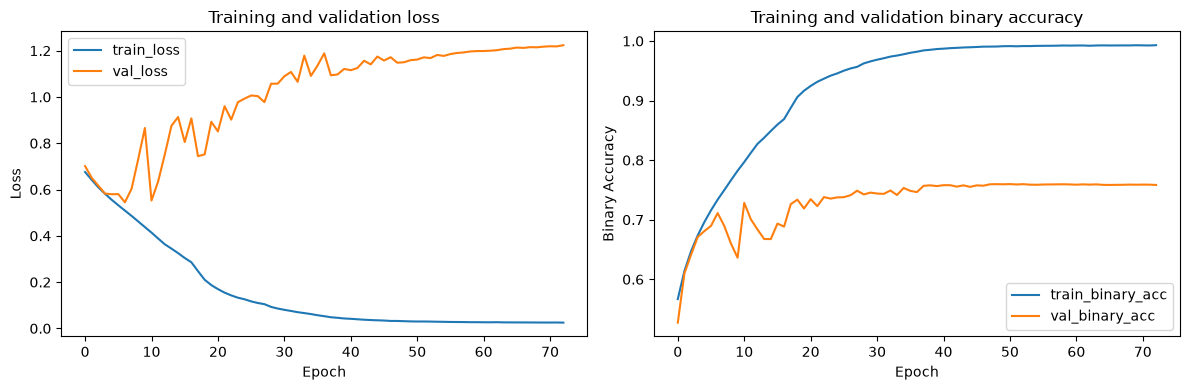

In [19]:
# Plot training history if available.

if "history" in globals():
    plt.figure(figsize=(12, 4))

    # Loss curve.
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="train_loss")
    plt.plot(history.history["val_loss"], label="val_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()

    # Binary accuracy curve.
    plt.subplot(1, 2, 2)
    plt.plot(history.history["binary_accuracy"], label="train_binary_acc")
    plt.plot(history.history["val_binary_accuracy"], label="val_binary_acc")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Accuracy")
    plt.title("Training and validation binary accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("No training history found.")

# 6. Evaluate the model

The test set is used only after training.

Important:

- `binary_accuracy` measures label-wise correctness.
- `precision` measures whether predicted labels are correct.
- `recall` measures whether true labels are found.
- `exact_match_accuracy` checks whether the whole label set is correct for each image.

For this task, precision, recall, and exact-match accuracy are usually more informative than binary accuracy.


In [20]:
# Evaluate the model on the test set.
results = multilabel_model.evaluate(x_test, y_test, verbose=1)

# print("\nTest results:")
# for name, value in zip(multilabel_model.metrics_names, results):
#     print(f"{name}: {value:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - binary_accuracy: 0.7644 - exact_match_accuracy: 0.0741 - loss: 1.1294 - precision: 0.7627 - recall: 0.7942


# 7. Visualize predictions

The model outputs probabilities.

Example:

```text
digit 0: 0.02
digit 1: 0.91
digit 2: 0.04
...
```

If a probability is greater than or equal to the threshold, that digit is predicted as present.

In [21]:
# Prediction helper functions
# Student donnt allow to change the threshold value
PREDICTION_THRESHOLD=0.5
def probs_to_digits(probs, threshold=PREDICTION_THRESHOLD):
    """Convert prediction probabilities into a list of predicted digits."""
    return np.where(probs >= threshold)[0].tolist()


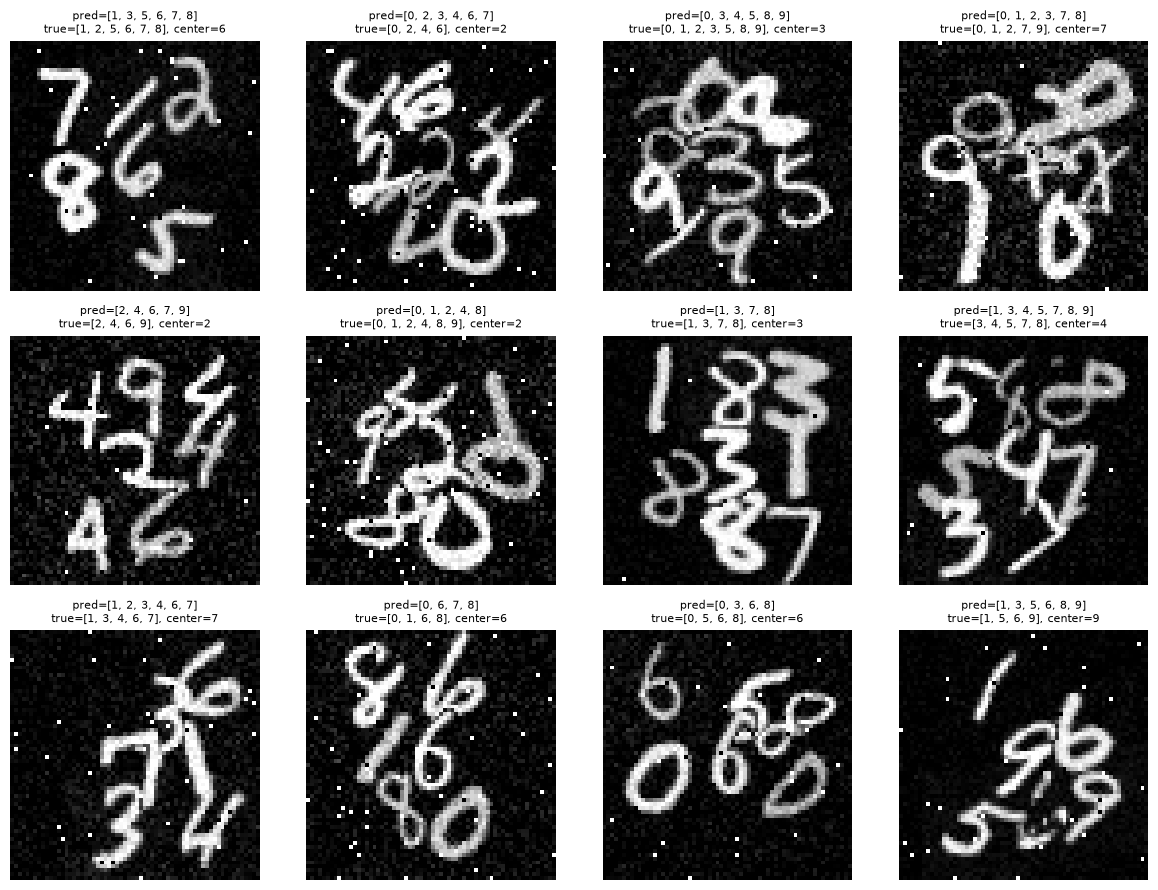

In [22]:

# Visualize several test predictions.

if "multilabel_model" in globals() and "x_test" in globals():
    indices = np.random.choice(len(x_test), size=12, replace=False)
    probs = multilabel_model.predict(x_test[indices], verbose=0)

    plt.figure(figsize=(12, 9))

    for i, idx in enumerate(indices):
        true_digits = multihot_to_digits(y_test[idx])
        pred_digits = probs_to_digits(probs[i], threshold=PREDICTION_THRESHOLD)
        center_label = meta_test["center_labels"][idx]

        plt.subplot(3, 4, i + 1)
        plt.imshow(x_test[idx].squeeze(), cmap="gray")
        plt.title(
            f"pred={pred_digits}\n"
            f"true={true_digits}, center={center_label}",
            fontsize=8,
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Model or test data not available.")


In [ ]:

# Inspect one test prediction in detail.
idx = 0
prob = multilabel_model.predict(x_test[idx:idx + 1], verbose=0)[0]

print("True digits:", multihot_to_digits(y_test[idx]))
print("Predicted digits:", probs_to_digits(prob))
print("Center label:", meta_test["center_labels"][idx])
print()

print("Prediction probabilities:")
for digit, p in enumerate(prob):
    print(f"digit {digit}: {p:.4f}")


True digits: [2, 3, 5, 7, 9]
Predicted digits: [2, 3, 5, 7, 9]
Center label: 7

Prediction probabilities:
digit 0: 0.0004
digit 1: 0.0001
digit 2: 0.9999
digit 3: 1.0000
digit 4: 0.0000
digit 5: 1.0000
digit 6: 0.0029
digit 7: 1.0000
digit 8: 0.0372
digit 9: 0.8280


: 

In [ ]:
# Exit kernel
import os
os.kill(os.getpid(), 9)